# Thực nghiệm N quân hậu

Notebook đọc bộ số liệu dùng trong báo cáo tại task1/results. Bộ này có 300 lượt, với 20 lượt cho mỗi kích thước và thuật toán. Hai biến thể Min-Conflicts dùng cùng chuỗi bàn khởi tạo với các seed 2026–2045.

Glucose3 đo riêng thời gian solve() sau khi nạp CNF. Min-Conflicts đo cả khởi tạo và các lần khởi động lại. Chạy mục 4 trong menu để đo lại và xem kết quả mới trong task1/benchmark-output.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt

task_dir = Path('.') if Path('experiments.ipynb').is_file() else Path('task1')
summary_path = task_dir / 'results' / 'summary.csv'
with summary_path.open(encoding='utf-8', newline='') as stream:
    summary = {(int(row['n']), row['algorithm']): row
               for row in csv.DictReader(stream)}
sizes = sorted({n for n, _ in summary})


In [2]:
print('Glucose3: trung bình 20 lượt cho mỗi N')
print(f"{'N':>3} | {'Biến':>5} | {'Mệnh đề':>8} | {'solve() (ms)':>12} | Nghiệm hợp lệ")
for n in sizes:
    row = summary[n, 'glucose3']
    elapsed = float(row['mean_seconds']) * 1000
    print(f"{n:>3} | {n*n:>5} | {row['clauses']:>8} | {elapsed:>12.4f} | {float(row['success_rate']):.0%}")


Glucose3: trung bình 20 lượt cho mỗi N
  N |  Biến |  Mệnh đề | solve() (ms) | Nghiệm hợp lệ
  4 |    16 |       80 |       0.0062 | 100%
  8 |    64 |      736 |       0.0344 | 100%
 16 |   256 |     6336 |       1.0878 | 100%
 32 |  1024 |    52608 |      12.9204 | 100%
 64 |  4096 |   428800 |     152.6832 | 100%


In [3]:
labels = {'standard': 'Chuẩn', 'max_conflict': 'Max-conflict'}
print('Min-Conflicts: 20 lượt cho mỗi cấu hình và mỗi N')
print(f"{'N':>3} | {'Thuật toán':<12} | {'ms TB':>8} | {'Bước TB':>8} | {'Trung vị':>8} | Restart | Nghiệm")
for n in sizes:
    for algorithm, label in labels.items():
        row = summary[n, algorithm]
        elapsed = float(row['mean_seconds']) * 1000
        print(f"{n:>3} | {label:<12} | {elapsed:>8.4f} | "
              f"{float(row['mean_steps']):>8.2f} | {float(row['median_steps']):>8.1f} | "
              f"{row['trials_with_restart']:>7} | {float(row['success_rate']):.0%}")


Min-Conflicts: 20 lượt cho mỗi cấu hình và mỗi N
  N | Thuật toán   |    ms TB |  Bước TB | Trung vị | Restart | Nghiệm
  4 | Chuẩn        |   0.0416 |     7.40 |      6.0 |       0 | 100%
  4 | Max-conflict |   0.0447 |     7.55 |      5.0 |       0 | 100%
  8 | Chuẩn        |   3.5220 |  1103.15 |     44.0 |       2 | 100%
  8 | Max-conflict |   5.8855 |  1575.45 |     30.5 |       3 | 100%
 16 | Chuẩn        |   0.5442 |    95.60 |     84.0 |       0 | 100%
 16 | Max-conflict |   6.1647 |  1084.65 |     61.0 |       2 | 100%
 32 | Chuẩn        |   0.9424 |    97.15 |     85.5 |       0 | 100%
 32 | Max-conflict |   0.8170 |    77.40 |     82.0 |       0 | 100%
 64 | Chuẩn        |   2.2594 |   127.25 |    120.0 |       0 | 100%
 64 | Max-conflict |   2.0700 |   112.00 |    100.5 |       0 | 100%


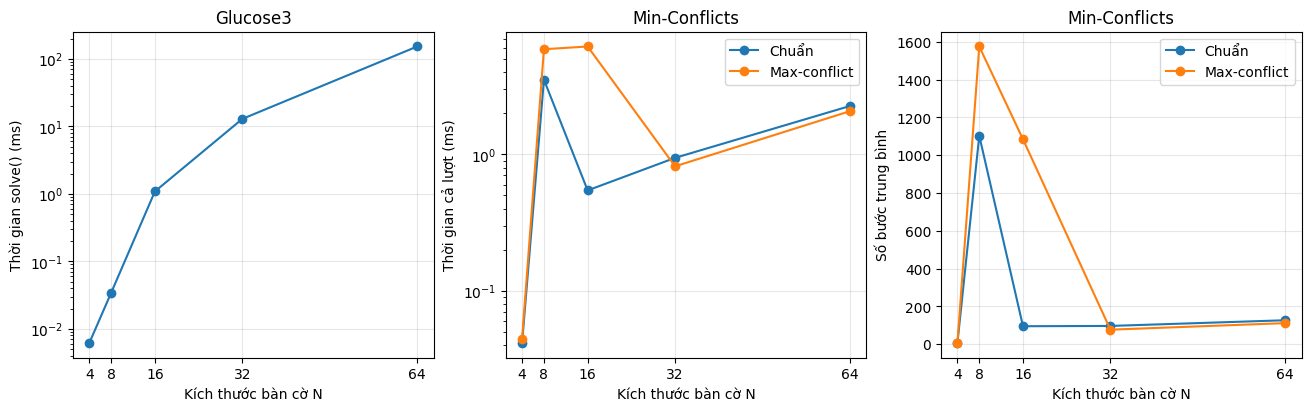

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
axes[0].plot(sizes, [1000 * float(summary[n, 'glucose3']['mean_seconds'])
                   for n in sizes], marker='o')
for algorithm, label in labels.items():
    axes[1].plot(sizes, [1000 * float(summary[n, algorithm]['mean_seconds'])
                        for n in sizes], marker='o', label=label)
    axes[2].plot(sizes, [float(summary[n, algorithm]['mean_steps'])
                        for n in sizes], marker='o', label=label)

for ax, title, ylabel in zip(
    axes,
    ('Glucose3', 'Min-Conflicts', 'Min-Conflicts'),
    ('Thời gian solve() (ms)', 'Thời gian cả lượt (ms)', 'Số bước trung bình')
):
    ax.set(title=title, xlabel='Kích thước bàn cờ N', ylabel=ylabel)
    ax.set_xticks(sizes)
    ax.grid(alpha=0.3)
axes[0].set_yscale('log')
axes[1].set_yscale('log')
axes[1].legend()
axes[2].legend()
plt.show()
